# Series temporales con pandas: la altura de la ISS durante un año


In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
with open('../datos/historia_iss.json', encoding='utf-8') as archivo:
    omms = json.load(archivo)

print('total:', len(omms))
type(omms[0])

total: 1420


dict

## ejercicio! 
ver qué campos hay en común con los registros omms que usamos en el proyecto:

In [6]:
# lista de diccionarios: ideal para pandas!
df = pd.DataFrame(omms)
print('total filas:', len(df))
df.head(5)
# df[['OBJECT_ID', 'APOAPSIS']]

total filas: 1420


,CCSDS_OMM_VERS,COMMENT,CREATION_DATE,ORIGINATOR,OBJECT_NAME,OBJECT_ID,CENTER_NAME,REF_FRAME,TIME_SYSTEM,MEAN_ELEMENT_THEORY,...,RCS_SIZE,COUNTRY_CODE,LAUNCH_DATE,SITE,DECAY_DATE,FILE,GP_ID,TLE_LINE0,TLE_LINE1,TLE_LINE2
0,3.0,GENERATED VIA SPACE-TRACK.ORG API,2025-11-11T04:56:40,18 SPCS,ISS (ZARYA),1998-067A,EARTH,TEME,UTC,SGP4,...,LARGE,CIS,1998-11-20,TTMTR,None,4877201,302254556,0 ISS (ZARYA),1 25544U 98067A 25314.80673003 .00011159 0...,2 25544 51.6337 300.5531 0004137 56.1394 303...
1,3.0,GENERATED VIA SPACE-TRACK.ORG API,2025-11-11T13:10:28,18 SPCS,ISS (ZARYA),1998-067A,EARTH,TEME,UTC,SGP4,...,LARGE,CIS,1998-11-20,TTMTR,None,4877249,302285896,0 ISS (ZARYA),1 25544U 98067A 25315.25818480 .00012468 0...,2 25544 51.6338 298.3179 0004133 57.8977 302...
2,3.0,GENERATED VIA SPACE-TRACK.ORG API,2025-11-12T10:14:37,18 SPCS,ISS (ZARYA),1998-067A,EARTH,TEME,UTC,SGP4,...,LARGE,CIS,1998-11-20,TTMTR,None,4877521,302317319,0 ISS (ZARYA),1 25544U 98067A 25316.22557474 .00019835 0...,2 25544 51.6334 293.5281 0004132 61.4658 298...
3,3.0,GENERATED VIA SPACE-TRACK.ORG API,2025-11-13T02:12:46,18 SPCS,ISS (ZARYA),1998-067A,EARTH,TEME,UTC,SGP4,...,LARGE,CIS,1998-11-20,TTMTR,None,4878500,302363210,0 ISS (ZARYA),1 25544U 98067A 25316.93497624 .00019039 0...,2 25544 51.6332 290.0154 0004116 64.1640 295...
4,3.0,GENERATED VIA SPACE-TRACK.ORG API,2025-11-13T06:46:20,18 SPCS,ISS (ZARYA),1998-067A,EARTH,TEME,UTC,SGP4,...,LARGE,CIS,1998-11-20,TTMTR,None,4878917,302398585,0 ISS (ZARYA),1 25544U 98067A 25316.93497624 .00019039 0...,2 25544 51.6332 290.0154 0004116 64.1640 295...


In [7]:
df.columns

Index(['CCSDS_OMM_VERS', 'COMMENT', 'CREATION_DATE', 'ORIGINATOR',
       'OBJECT_NAME', 'OBJECT_ID', 'CENTER_NAME', 'REF_FRAME', 'TIME_SYSTEM',
       'MEAN_ELEMENT_THEORY', 'EPOCH', 'MEAN_MOTION', 'ECCENTRICITY',
       'INCLINATION', 'RA_OF_ASC_NODE', 'ARG_OF_PERICENTER', 'MEAN_ANOMALY',
       'EPHEMERIS_TYPE', 'CLASSIFICATION_TYPE', 'NORAD_CAT_ID',
       'ELEMENT_SET_NO', 'REV_AT_EPOCH', 'BSTAR', 'MEAN_MOTION_DOT',
       'MEAN_MOTION_DDOT', 'SEMIMAJOR_AXIS', 'PERIOD', 'APOAPSIS', 'PERIAPSIS',
       'OBJECT_TYPE', 'RCS_SIZE', 'COUNTRY_CODE', 'LAUNCH_DATE', 'SITE',
       'DECAY_DATE', 'FILE', 'GP_ID', 'TLE_LINE0', 'TLE_LINE1', 'TLE_LINE2'],
      dtype='str')

In [9]:
columnas = ['EPOCH', 'MEAN_MOTION', 'ECCENTRICITY', 'SEMIMAJOR_AXIS', 'PERIAPSIS', 'APOAPSIS', 'PERIOD']
df = df[ columnas]          # nos quedamos con lo que vamos a usar
df.head(5)

,EPOCH,MEAN_MOTION,ECCENTRICITY,SEMIMAJOR_AXIS,PERIAPSIS,APOAPSIS,PERIOD
0,2025-11-10T19:21:41.474592,15.49512626,0.00041371,6796.288,415.341,420.965,92.932
1,2025-11-11T06:11:47.166720,15.49525392,0.00041335,6796.250,415.306,420.925,92.932
2,2025-11-12T05:24:49.657536,15.49560899,0.00041322,6796.147,415.203,420.820,92.930
3,2025-11-12T22:26:21.947136,15.49593679,0.00041155,6796.051,415.119,420.713,92.928
4,2025-11-12T22:26:21.947136,15.49593679,0.00041160,6796.051,415.119,420.713,92.928


In [13]:
df[columnas[1:]] = df[columnas[1:]].astype(float)

df['EPOCH'] = pd.to_datetime(df['EPOCH'], utc=True)
df.head(4)

,EPOCH,MEAN_MOTION,ECCENTRICITY,SEMIMAJOR_AXIS,PERIAPSIS,APOAPSIS,PERIOD
0,2025-11-10 19:21:41.474592+00:00,15.495126,0.000414,6796.288,415.341,420.965,92.932
1,2025-11-11 06:11:47.166720+00:00,15.495254,0.000413,6796.250,415.306,420.925,92.932
2,2025-11-12 05:24:49.657536+00:00,15.495609,0.000413,6796.147,415.203,420.820,92.930
3,2025-11-12 22:26:21.947136+00:00,15.495937,0.000412,6796.051,415.119,420.713,92.928


In [14]:
df['EPOCH'].is_monotonic_increasing # ordenados?

True

In [15]:
df = df.set_index('EPOCH')
df.head(5)

,MEAN_MOTION,ECCENTRICITY,SEMIMAJOR_AXIS,PERIAPSIS,APOAPSIS,PERIOD
EPOCH,,,,,,
2025-11-10 19:21:41.474592+00:00,15.495126,0.000414,6796.288,415.341,420.965,92.932
2025-11-11 06:11:47.166720+00:00,15.495254,0.000413,6796.250,415.306,420.925,92.932
2025-11-12 05:24:49.657536+00:00,15.495609,0.000413,6796.147,415.203,420.820,92.930
2025-11-12 22:26:21.947136+00:00,15.495937,0.000412,6796.051,415.119,420.713,92.928
2025-11-12 22:26:21.947136+00:00,15.495937,0.000412,6796.051,415.119,420.713,92.928


## Datos muy cercanos o repetidos
Redondeamos el índice a 1 minuto

In [19]:
df.index.round('5min')[:5]

DatetimeIndex(['2025-11-10 19:20:00+00:00', '2025-11-11 06:10:00+00:00',
               '2025-11-12 05:25:00+00:00', '2025-11-12 22:25:00+00:00',
               '2025-11-12 22:25:00+00:00'],
              dtype='datetime64[us, UTC]', name='EPOCH', freq=None)

In [20]:
repetidos = df.index.round('min').duplicated()
repetidos[:10]

array([False, False, False, False,  True, False, False,  True, False,
       False])

In [22]:
print('antes',len(df))
df = df[~repetidos]  #me quedo con los que no están repetidos!
print(len(df), 'registros únicos')

antes 1420
1023 registros únicos


## La altura

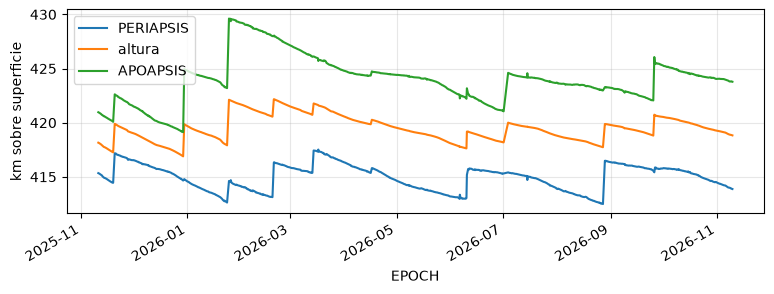

In [23]:
df['altura'] = (df['PERIAPSIS']+df['APOAPSIS'])/2  # altura promedio sobre superficie

df[['PERIAPSIS', 'altura', 'APOAPSIS']].plot(figsize=(9, 3))
plt.ylabel('km sobre superficie')
plt.grid(alpha=0.3)
plt.show()

Se ve lo que contaba la consigna del proyecto: la ISS baja de a poco por el roce con la atmósfera, y cada tanto se encienden motores para subirla (un reboost)

## Elegir por fecha

Con un índice de fechas, `.loc` acepta texto. Un mes entero, sin escribir días:

In [27]:
septiembre = df.loc['2026-09-20':'2026-09-30'] # dataframe nuevo!
print(len(septiembre), 'registros en septiembre')

28 registros en septiembre


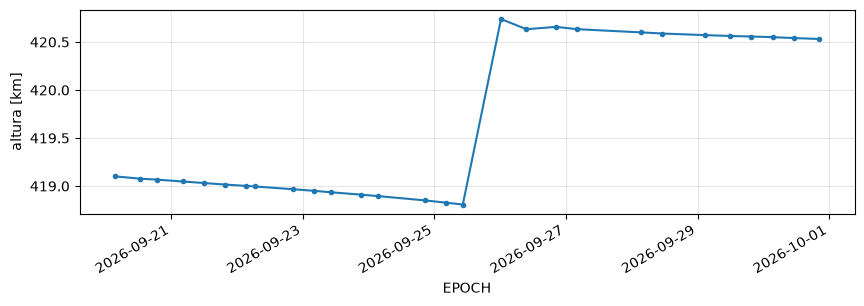

In [28]:
septiembre['altura'].plot(marker='.', figsize=(10, 3))
plt.ylabel('altura [km]')
plt.grid(alpha=0.3)
plt.show()

In [123]:
# a diferencia del slicing en listas, el final se incluye
df.loc['2026-01-23':'2026-01-24', ['altura', 'PERIAPSIS', 'APOAPSIS']]

,altura,PERIAPSIS,APOAPSIS
EPOCH,,,
2026-01-23 09:35:38.687712+00:00,417.9455,412.680,423.211
2026-01-23 17:19:58.588032+00:00,417.9080,412.623,423.193
2026-01-24 19:40:05.974176+00:00,422.1165,414.618,429.615


## Una serie irregular

Los `EPOCH` llegan cuando llegan. ¿Cada cuánto?

In [32]:
df.index[:5]

DatetimeIndex(['2025-11-10 19:21:41.474592+00:00',
               '2025-11-11 06:11:47.166720+00:00',
               '2025-11-12 05:24:49.657536+00:00',
               '2025-11-12 22:26:21.947136+00:00',
               '2025-11-13 04:37:49.663488+00:00'],
              dtype='datetime64[us, UTC]', name='EPOCH', freq=None)

In [34]:
intervalos = df.index.diff()

intervalos.to_series().describe()

count                      1022
mean     0 days 08:32:56.473555
std      0 days 04:49:20.487298
min      0 days 01:32:50.706528
25%      0 days 06:11:32.633160
50%      0 days 07:44:29.708016
75%      0 days 09:17:38.690304
max      2 days 13:56:10.731264
Name: EPOCH, dtype: object

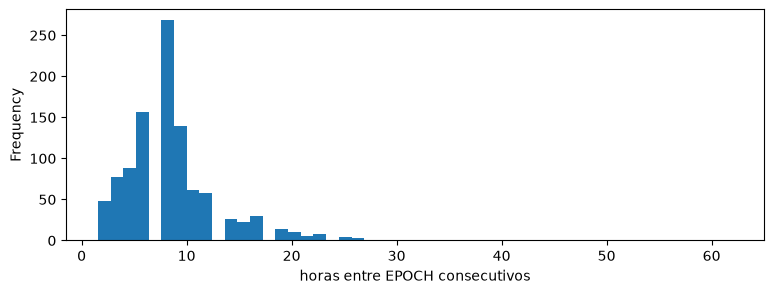

In [37]:
# un Timedelta se pasa a horas con total_seconds
horas = intervalos.to_series().dt.total_seconds() / 3600
horas.plot.hist(bins=50, figsize=(9,3))
plt.xlabel('horas entre EPOCH consecutivos')
plt.show()

In [14]:
# los huecos más largos: ¿cuándo terminan y cuánto duraron?
intervalos.sort_values(ascending=False).head(5)

EPOCH
2026-07-04 02:07:57.020160+00:00   2 days 13:56:10.731264
2026-10-25 11:59:10.479840+00:00   1 days 06:57:59.330592
2026-08-05 00:31:32.592000+00:00   1 days 05:24:44.750016
2026-06-21 13:48:54.457920+00:00   1 days 03:51:51.700320
2026-01-24 19:40:05.974176+00:00   1 days 02:20:07.386144
Name: EPOCH, dtype: timedelta64[us]

## Empujones: los reboosts

Un reboost es un salto en altura entre un registro y el siguiente, lo vemos con  `.diff()` restando cada fila con la anterior:

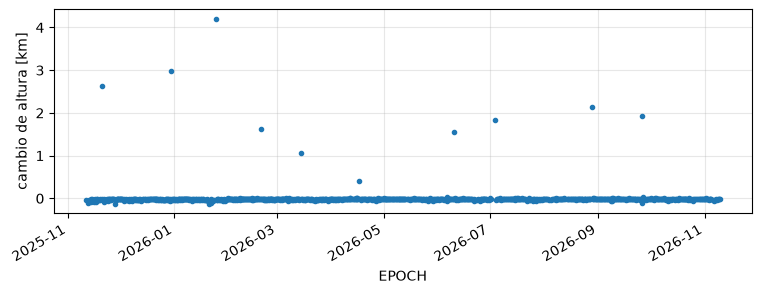

In [126]:
salto = df['altura'].diff()
salto.plot(figsize=(9, 3), marker='.', linestyle='none')
plt.ylabel('cambio de altura [km]')
plt.grid(alpha=0.3)
plt.show()

In [127]:
reboosts = salto[salto > 0.2]       # más de medio kilómetro de subida
reboosts

EPOCH
2025-11-20 05:19:55.100064+00:00    2.6350
2025-12-30 03:29:51.548064+00:00    2.9720
2026-01-24 19:40:05.974176+00:00    4.2085
2026-02-19 13:41:39.876288+00:00    1.6135
2026-03-14 10:01:48.497952+00:00    1.0530
2026-04-16 20:16:06.008736+00:00    0.4140
2026-06-10 09:59:31.701696+00:00    1.5550
2026-07-04 02:07:57.020160+00:00    1.8255
2026-08-28 15:03:31.768992+00:00    2.1475
2026-09-26 00:18:14.180832+00:00    1.9315
Name: altura, dtype: float64

In [129]:
print(len(reboosts), 'reboosts en total')
print('salto medio:', reboosts.mean().round(2), 'km')

# restar fechas da Timedelta
reboosts.index.to_series().diff()

10 reboosts en total
salto medio: 2.04 km


EPOCH
2025-11-20 05:19:55.100064+00:00                       NaT
2025-12-30 03:29:51.548064+00:00   39 days 22:09:56.448000
2026-01-24 19:40:05.974176+00:00   25 days 16:10:14.426112
2026-02-19 13:41:39.876288+00:00   25 days 18:01:33.902112
2026-03-14 10:01:48.497952+00:00   22 days 20:20:08.621664
2026-04-16 20:16:06.008736+00:00   33 days 10:14:17.510784
2026-06-10 09:59:31.701696+00:00   54 days 13:43:25.692960
2026-07-04 02:07:57.020160+00:00   23 days 16:08:25.318464
2026-08-28 15:03:31.768992+00:00   55 days 12:55:34.748832
2026-09-26 00:18:14.180832+00:00   28 days 09:14:42.411840
Name: EPOCH, dtype: timedelta64[us]

## Regularizar para comparar `resample`

Para comparar con otra serie, o para tener "un dato por día", hay que pasar a una grilla regular. `resample('D')` agrupa por día, después hay que decir qué hacer con cada grupo. (lo mismo se puede hacer con `.groupby`)

Frecuencias más usadas: `'1h'`, `'6h'`, `'D'` (día), `'W'` (semana), `'MS'` (mes).

In [131]:
diaria = df['altura'].resample('D').mean()
diaria.head()

EPOCH
2025-11-10 00:00:00+00:00    418.15300
2025-11-11 00:00:00+00:00    418.11550
2025-11-12 00:00:00+00:00    417.96375
2025-11-13 00:00:00+00:00    417.82850
2025-11-14 00:00:00+00:00    417.73850
Freq: D, Name: altura, dtype: float64

In [132]:
# los días sin ningún EPOCH quedan en NaN
print(diaria.isna().sum(), 'días sin datos')
diaria[diaria.isna()]

3 días sin datos


EPOCH
2026-07-02 00:00:00+00:00   NaN
2026-07-03 00:00:00+00:00   NaN
2026-08-04 00:00:00+00:00   NaN
Name: altura, dtype: float64

In [133]:
# igual que groupby, agg calcula varias cosas a la vez
df['altura'].resample('MS').agg(registros='count', minima='min', media='mean', maxima='max')

,registros,minima,media,maxima
EPOCH,,,,
2025-11-01 00:00:00+00:00,52,417.2615,418.736115,419.8965
2025-12-01 00:00:00+00:00,92,416.8905,418.061913,419.8625
2026-01-01 00:00:00+00:00,84,417.9080,419.617012,422.1165
2026-02-01 00:00:00+00:00,102,420.5555,421.351211,422.1690
2026-03-01 00:00:00+00:00,91,420.5665,421.161203,421.7765
2026-04-01 00:00:00+00:00,88,419.5460,420.029886,420.5595
2026-05-01 00:00:00+00:00,93,418.1085,418.935952,419.5210
2026-06-01 00:00:00+00:00,79,417.6225,418.402253,419.1800
2026-07-01 00:00:00+00:00,76,418.1800,419.467072,420.0055


## ¿Cuánto baja por día?

Con la serie diaria, `.diff()` da cuántos km cambió de un día al otro. Los días de reboost dan positivo: los sacamos con `.where` (deja `NaN` donde la condición es falsa).

In [134]:
cambio_diario = diaria.interpolate().diff()      # interpolate rellena los días sin dato (quedaro en NaN con el resample())
caida = cambio_diario.where(cambio_diario < 0)    # sólo los días que bajó

print('baja típica:', caida.median().round(2), 'km por día')

baja típica: -0.05 km por día


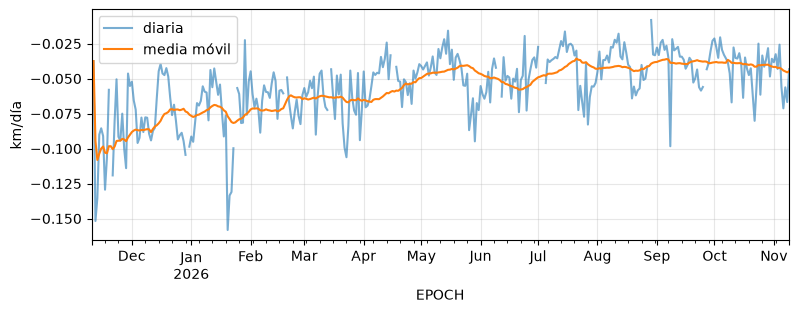

In [136]:
# ¿baja siempre igual? promedio móvil de 30 días
caida.plot(figsize=(9, 3), alpha=0.6, label='diaria')
caida.rolling('30D').mean().plot(label='media móvil')
plt.ylabel('km/día')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

La caída no es constante: depende de la densidad de la atmósfera a 400 km, que aumenta cuando el Sol está más activo.

## Zona horaria

Las fechas están en UTC. ¿A qué hora argentina fue cada reboost (al menos, el primer `EPOCH` después del encendido)?

In [137]:
reboosts.tz_convert('America/Argentina/Buenos_Aires')

EPOCH
2025-11-20 02:19:55.100064-03:00    2.6350
2025-12-30 00:29:51.548064-03:00    2.9720
2026-01-24 16:40:05.974176-03:00    4.2085
2026-02-19 10:41:39.876288-03:00    1.6135
2026-03-14 07:01:48.497952-03:00    1.0530
2026-04-16 17:16:06.008736-03:00    0.4140
2026-06-10 06:59:31.701696-03:00    1.5550
2026-07-03 23:07:57.020160-03:00    1.8255
2026-08-28 12:03:31.768992-03:00    2.1475
2026-09-25 21:18:14.180832-03:00    1.9315
Name: altura, dtype: float64

## 10. Arsat y starlinks

En `datos/` hay dos historias más: `ARSAT 1` (geoestacionario) y un Starlink que ya reingresó. Como vamos a repetir la lectura y limpieza, y metemos todo en una función:

In [138]:
def leer_historia(ruta):
    '''Lee un JSON de historia de Space-Track y devuelve un DataFrame limpio,
    indexado por EPOCH, con la columna altura (km).'''
    with open(ruta, encoding='utf-8') as archivo:
        tabla = pd.DataFrame(json.load(archivo))
    print(tabla['OBJECT_NAME'].iloc[0], '-', len(tabla), 'registros')
    tabla = tabla[['EPOCH'] + columnas]
    tabla[columnas] = tabla[columnas].astype(float)
    tabla['EPOCH'] = pd.to_datetime(tabla['EPOCH'], utc=True)
    tabla = tabla.set_index('EPOCH').sort_index()
    tabla = tabla[~tabla.index.round('1min').duplicated()]
    tabla['altura'] = (tabla['PERIAPSIS']+ tabla['APOAPSIS'])/2
    return tabla

arsat = leer_historia('../datos/historia_arsat1.json')
starlink = leer_historia('../datos/historia_starlink.json')

ARSAT 1 - 1338 registros
STARLINK-4607 - 639 registros


### ARSAT 1: quieto a 35.787 km

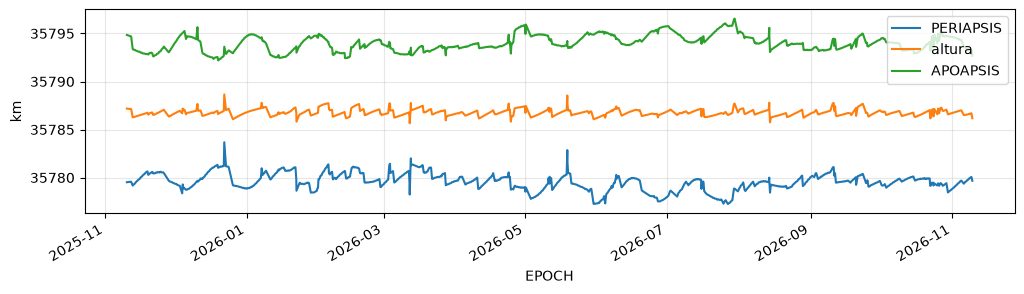

count     1175.000000
mean     35786.766201
std          0.333539
min      35785.652000
25%      35786.545500
50%      35786.731500
75%      35786.955000
max      35788.652500
Name: altura, dtype: float64

In [139]:
arsat[['PERIAPSIS', 'altura', 'APOAPSIS']].plot(figsize=(12, 3))
plt.ylabel('km')
plt.grid(alpha=0.3)
plt.show()

arsat['altura'].describe()

In [146]:
# el período de un geoestacionario: una vuelta por día (sideral: 23 h 56 min)
(arsat['PERIOD'].mean() / 60).round(2)

np.float64(23.94)

La altura varía apenas ±1 km en todo el año: a 36.000 km no hay atmósfera que lo frene, y los motores lo mantienen en su lugar.

### Starlink cayendo: de 540 km a la atmósfera

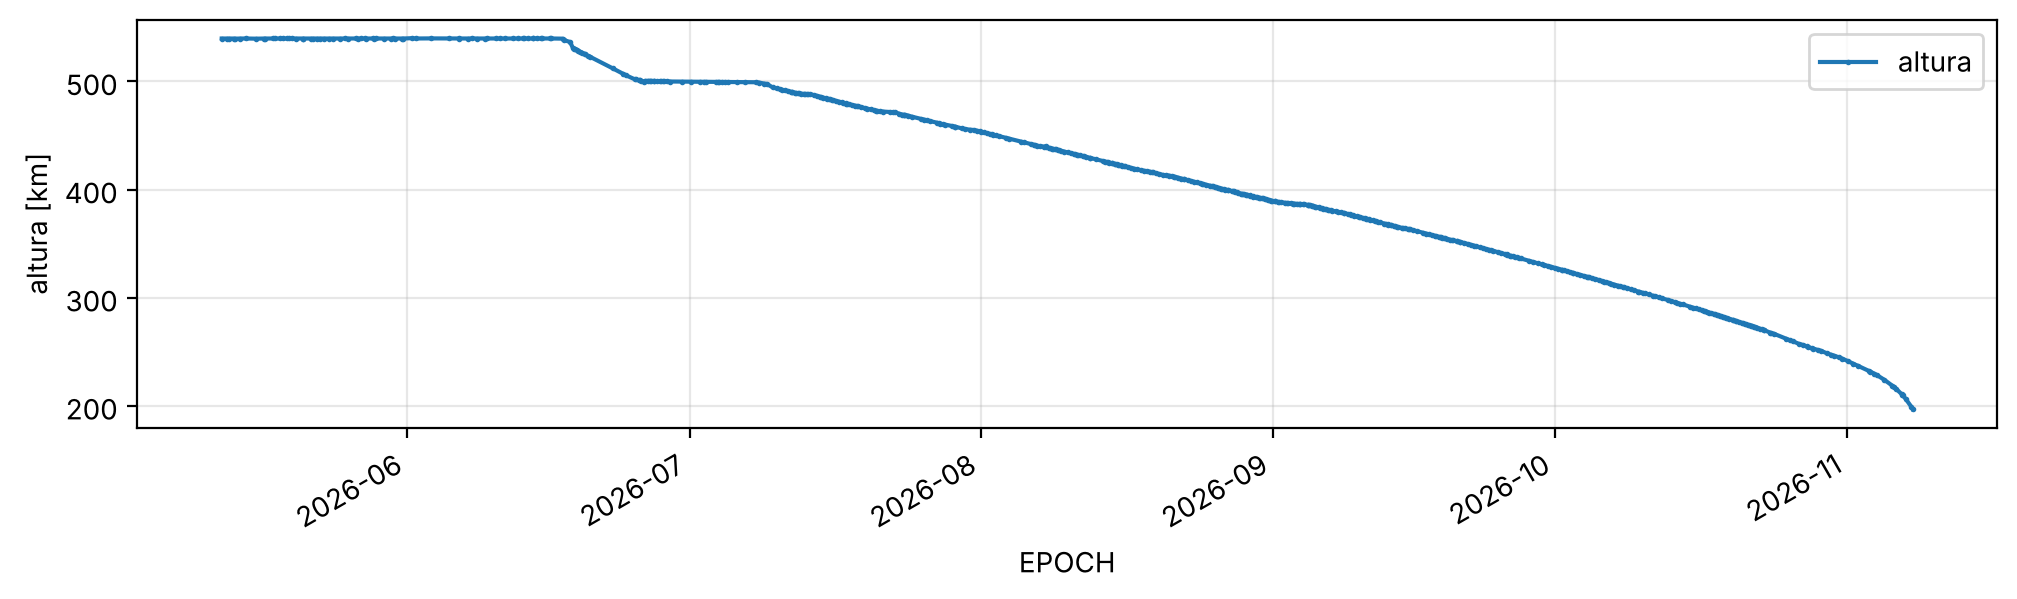

primer dato: 2026-05-12 06:31:02.940384+00:00 539.7 km
último dato: 2026-11-07 23:21:39.358944+00:00 197.1 km


In [27]:
starlink[['altura']].plot(figsize=(12, 3), marker='.', markersize=2)
plt.ylabel('altura [km]')
plt.grid(alpha=0.3)
plt.show()

print('primer dato:', starlink.index[0], starlink['altura'].iloc[0].round(1), 'km')
print('último dato:', starlink.index[-1], starlink['altura'].iloc[-1].round(1), 'km')

Hay tres etapas: en órbita a 540 km, una bajada súbita con motores (mediados de junio, con una pausa en 500 km), y después la caída libre por el roce con la atmósfera, que se va acelerando.

¿Cuánto baja por día? Mismo método que con la ISS:

In [147]:
caida_sl = starlink['altura'].resample('D').mean().interpolate().diff()
caida_sl.resample('MS').mean()     # km por día, promedio de cada mes

EPOCH
2026-05-01 00:00:00+00:00   -0.000026
2026-06-01 00:00:00+00:00   -1.327933
2026-07-01 00:00:00+00:00   -1.470851
2026-08-01 00:00:00+00:00   -2.058622
2026-09-01 00:00:00+00:00   -2.052211
2026-10-01 00:00:00+00:00   -2.726734
2026-11-01 00:00:00+00:00   -6.216560
Freq: MS, Name: altura, dtype: float64

Cuanto más abajo, más densa la atmósfera y más rápido cae.

### ISS y Starlink juntos

Dos series con `EPOCH` distintos no se pueden poner lado a lado directamente. Pasadas a diarias, comparten el índice, y al armar un DataFrame pandas alinea por fecha: donde una serie no tiene dato, pone `NaN`.

In [149]:
juntas = pd.DataFrame({
    'ISS': df['altura'].resample('D').mean(),
    'Starlink': starlink['altura'].resample('D').mean(),
})
juntas.loc['2026-05-10':'2026-05-15']

,ISS,Starlink
EPOCH,,
2026-05-10 00:00:00+00:00,419.144500,NaN
2026-05-11 00:00:00+00:00,419.109000,NaN
2026-05-12 00:00:00+00:00,419.081333,539.742500
2026-05-13 00:00:00+00:00,419.059500,539.696833
2026-05-14 00:00:00+00:00,419.027250,539.750750
2026-05-15 00:00:00+00:00,419.011500,539.592500


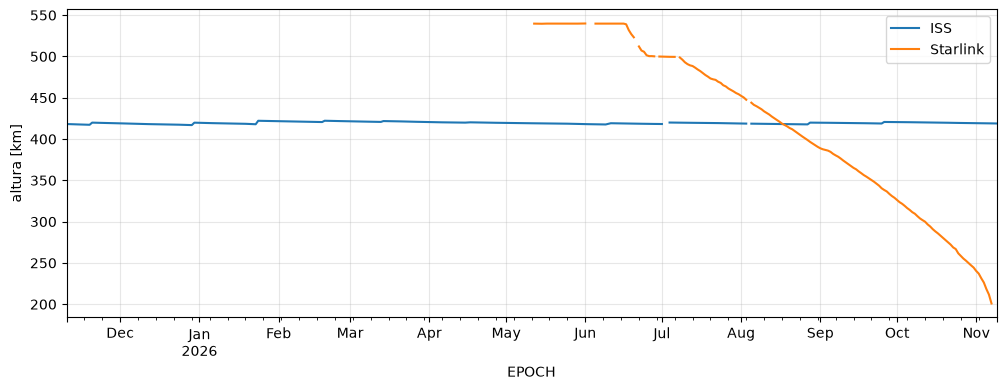

In [150]:
juntas.plot(figsize=(12, 4))
plt.ylabel('altura [km]')
plt.grid(alpha=0.3)
plt.show()

## Resumen

|  |  |
|---|---|
| texto a fecha | `pd.to_datetime(df['EPOCH'], utc=True)` |
| un tramo de tiempo | `df.loc['2026-01']`, `df.loc['2026-01-23':'2026-01-26']` |
| diferencia entre filas | `.diff()` (con fechas da `Timedelta`) |
| `Timedelta` a número | `.dt.total_seconds()` |
| sacar repetidos | `df[~df.index.duplicated()]` |
| pasar a paso regular | `.resample('D').mean()` / `.agg(...)` |
| promedio móvil | `.rolling('30D').mean()` |
| rellenar huecos | `.interpolate()` |
| descartar valores | `.where(condicion)` |
| hora local | `.tz_convert('America/Argentina/Buenos_Aires')` |
| juntar series con fechas distintas | `pd.DataFrame({'a': serie_a, 'b': serie_b})` (alinea por índice) |

## Ejercicios


-  ¿Cuántos km bajó la ISS en total en el año, y cuántos subió?
- Buscar las maniobras de ARSAT 1: saltos en `ECCENTRICITY` o en `PERIAPSIS`. ¿Cada cuánto corrige su órbita?
- ¿Cuántos días tardó el Starlink en bajar de 400 a 300 km? ¿Y de 300 a 200?
